# 02 — Logistic Regression and Gaussian Naive Bayes
**Member 2.** Train, tune and evaluate Logistic Regression and Gaussian Naive Bayes on
all 30 original features, using the common protocol (5-fold stratified CV on the
training set; tuning criterion = malignant F1). The test set is not used here.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay
from common import *
from models import build_pipeline, display_name, GRIDS

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160, "display.max_columns", 40)
X_train, X_test, y_train, y_test = get_split()
del X_test, y_test  # not used during model development

## 1. Logistic Regression
Pipeline: `StandardScaler → LogisticRegression(liblinear)`.

Grid:
* `C` (inverse regularisation strength): 10⁻³ … 10³
* penalty: L2 (`l1_ratio=0`) or L1 (`l1_ratio=1`, sparse coefficients)
* `class_weight`: none or *balanced* (up-weights the minority malignant class)

In [2]:
lr_grid = GRIDS["logreg"]
lr_grid
lr_gs = tune(build_pipeline("logreg"), lr_grid, X_train, y_train)
print("best params:", lr_gs.best_params_)
print(f"best CV F1: {lr_gs.best_score_:.4f}")

best params: {'clf__C': np.float64(0.1), 'clf__class_weight': 'balanced', 'clf__l1_ratio': 0}
best CV F1: 0.9674


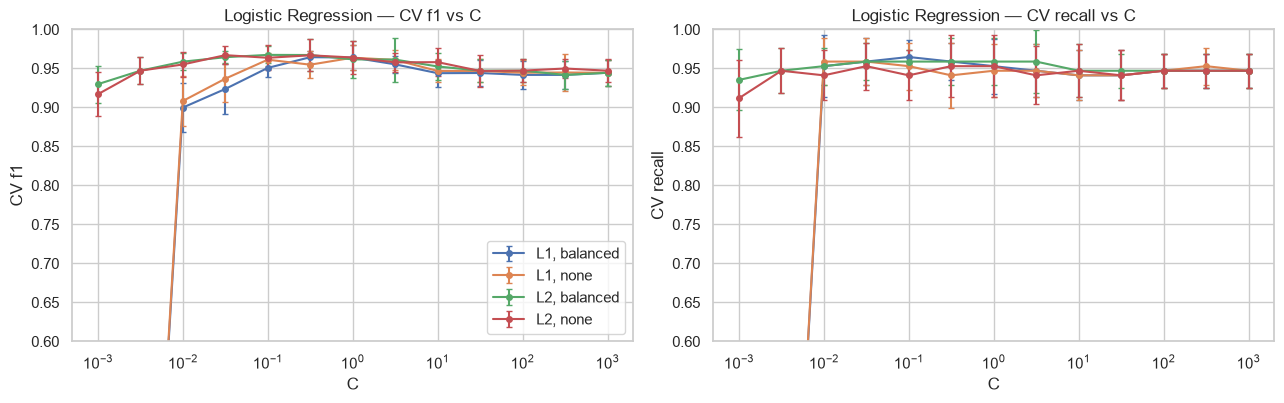

In [3]:
res = pd.DataFrame(lr_gs.cv_results_)
res["penalty"] = res["param_clf__l1_ratio"].map({0: "L2", 1: "L1"})
res["class_weight"] = res["param_clf__class_weight"].fillna("none")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True)
for ax, metric in zip(axes, ["f1", "recall"]):
    for (pen, cw), g in res.groupby(["penalty", "class_weight"]):
        ax.errorbar(g["param_clf__C"].astype(float), g[f"mean_test_{metric}"], yerr=g[f"std_test_{metric}"],
                    marker="o", ms=4, capsize=2, label=f"{pen}, {cw}")
    ax.set_xscale("log"); ax.set_xlabel("C"); ax.set_ylabel(f"CV {metric}")
    ax.set_title(f"Logistic Regression — CV {metric} vs C")
axes[0].legend(); axes[1].set_ylim(0.6, 1.0); axes[0].set_ylim(0.6, 1.0)
fig.tight_layout(); savefig(fig, "02_logreg_C_curve"); plt.show()

### L1 vs L2 regularisation (for comparison with notebook 06)
Best configuration for each penalty. L1 here is used as a *classifier* (sparse
weights learned jointly with the decision rule) — notebook 06 instead uses L1 only to
*select* features and then trains other classifiers on them.

In [4]:
rows = []
for pen, l1r in [("L2", 0), ("L1", 1)]:
    sub = res[res["param_clf__l1_ratio"] == l1r]
    i = sub["mean_test_f1"].idxmax()
    p = res.loc[i, "params"]
    pipe = build_pipeline("logreg", p).fit(X_train, y_train)
    nz = int((pipe.named_steps["clf"].coef_ != 0).sum())
    row = {"model": f"Logistic Regression ({pen})", "C": p["clf__C"], "class_weight": p["clf__class_weight"],
           "non_zero_coefs": nz}
    for m in METRICS:
        row[f"cv_{m}"] = res.loc[i, f"mean_test_{m}"]; row[f"cv_{m}_std"] = res.loc[i, f"std_test_{m}"]
    rows.append(row)
summarize(rows)

,model,C,class_weight,non_zero_coefs,accuracy,precision,recall,specificity,f1,roc_auc
0,Logistic Regression (L2),0.100000,balanced,30,0.9758 ± 0.0082,0.9766 ± 0.0215,0.9588 ± 0.0144,0.9860 ± 0.0131,0.9674 ± 0.0109,0.9949 ± 0.0056
1,Logistic Regression (L1),0.316228,balanced,9,0.9736 ± 0.0054,0.9709 ± 0.0176,0.9588 ± 0.0235,0.9825 ± 0.0111,0.9644 ± 0.0075,0.9941 ± 0.0046


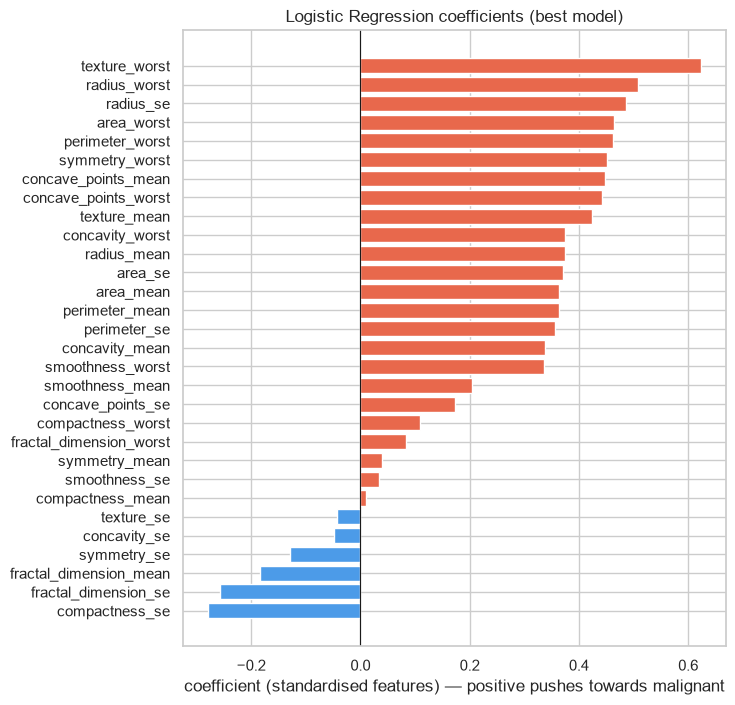

non-zero coefficients: 30 / 30


In [5]:
best_lr = lr_gs.best_estimator_
coefs = pd.Series(best_lr.named_steps["clf"].coef_[0], index=FEATURE_NAMES).sort_values()
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(coefs.index, coefs.values, color=np.where(coefs > 0, "#E8684C", "#4C9BE8"))
ax.axvline(0, color="k", lw=.8)
ax.set_xlabel("coefficient (standardised features) — positive pushes towards malignant")
ax.set_title("Logistic Regression coefficients (best model)")
savefig(fig, "02_logreg_coefficients"); plt.show()
print("non-zero coefficients:", int((coefs != 0).sum()), "/ 30")

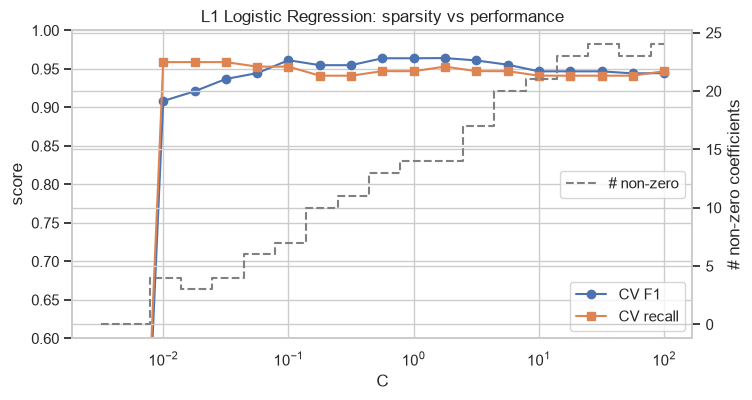

,C,non_zero,cv_accuracy,cv_recall,cv_f1,cv_roc_auc
0,0.0032,0,0.6264,0.0000,0.0000,0.5000
1,0.0056,0,0.6264,0.0000,0.0000,0.5000
2,0.0100,4,0.9275,0.9588,0.9083,0.9810
3,0.0178,3,0.9385,0.9588,0.9209,0.9838
4,0.0316,4,0.9516,0.9588,0.9369,0.9870
5,0.0562,6,0.9582,0.9529,0.9445,0.9903
6,0.1000,7,0.9714,0.9529,0.9613,0.9913
7,0.1778,10,0.9670,0.9412,0.9548,0.9930
8,0.3162,11,0.9670,0.9412,0.9548,0.9935
9,0.5623,13,0.9736,0.9471,0.9638,0.9949


In [6]:
sparsity = []
for C in np.logspace(-2.5, 2, 19):
    pipe = build_pipeline("logreg", {"clf__C": C, "clf__l1_ratio": 1})
    row = cv_evaluate(pipe, X_train, y_train, name="L1 LR", C=C)
    row["non_zero"] = int((pipe.fit(X_train, y_train).named_steps["clf"].coef_ != 0).sum())
    sparsity.append(row)
sp = pd.DataFrame(sparsity)
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(sp["C"], sp["cv_f1"], "o-", label="CV F1"); ax1.plot(sp["C"], sp["cv_recall"], "s-", label="CV recall")
ax1.set_xscale("log"); ax1.set_xlabel("C"); ax1.set_ylabel("score"); ax1.set_ylim(0.6, 1.0)
ax2 = ax1.twinx(); ax2.step(sp["C"], sp["non_zero"], where="mid", color="grey", ls="--", label="# non-zero")
ax2.set_ylabel("# non-zero coefficients")
ax1.legend(loc="lower right"); ax2.legend(loc="center right")
ax1.set_title("L1 Logistic Regression: sparsity vs performance")
savefig(fig, "02_l1_sparsity_path"); plt.show()
sp[["C", "non_zero", "cv_accuracy", "cv_recall", "cv_f1", "cv_roc_auc"]].round(4)

## 2. Gaussian Naive Bayes
GNB assumes each feature is normally distributed within each class and that features
are *conditionally independent*. Both assumptions are clearly violated here (skewed
features, r > 0.99 between radius/perimeter/area), so we expect it to be weaker than
the discriminative models. The only hyper-parameter is `var_smoothing`
(a fraction of the largest variance added to every variance for stability).
Scaling does not change GNB's decisions but is kept for a uniform pipeline.

In [7]:
gnb_grid = GRIDS["gnb"]
gnb_gs = tune(build_pipeline("gnb"), gnb_grid, X_train, y_train)
print("best params:", gnb_gs.best_params_)
print(f"best CV F1: {gnb_gs.best_score_:.4f}")

best params: {'clf__var_smoothing': np.float64(0.03162277660168379)}
best CV F1: 0.9214


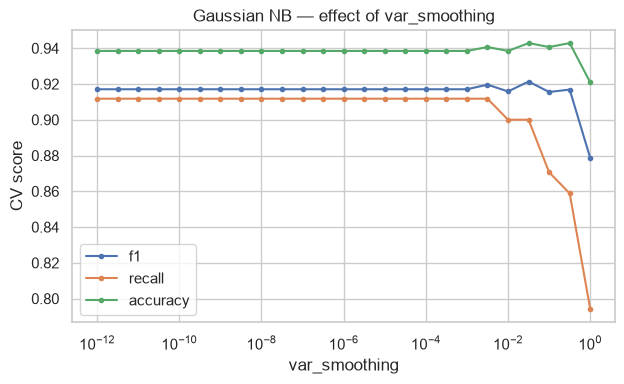

In [8]:
r = pd.DataFrame(gnb_gs.cv_results_)
fig, ax = plt.subplots(figsize=(7, 3.8))
for m in ["f1", "recall", "accuracy"]:
    ax.plot(r["param_clf__var_smoothing"].astype(float), r[f"mean_test_{m}"], "o-", ms=3, label=m)
ax.set_xscale("log"); ax.set_xlabel("var_smoothing"); ax.set_ylabel("CV score"); ax.legend()
ax.set_title("Gaussian NB — effect of var_smoothing")
savefig(fig, "02_gnb_var_smoothing"); plt.show()

### Does removing redundant features help Naive Bayes?
Hypothesis: because the independence assumption is broken by near-duplicate features, a quick
check: keep only one of each {radius, perimeter, area} triple (drop perimeter and area).

In [9]:
drop = [f for f in FEATURE_NAMES if f.startswith(("perimeter_", "area_"))]
reduced = [f for f in FEATURE_NAMES if f not in drop]
gnb_red = build_pipeline("gnb", gnb_gs.best_params_)
summarize([
    best_cv_row(gnb_gs, "Gaussian NB (30 features)"),
    cv_evaluate(gnb_red, X_train[reduced], y_train, name=f"Gaussian NB ({len(reduced)} features, no perimeter/area)"),
])

,model,accuracy,precision,recall,specificity,f1,roc_auc
0,Gaussian NB (30 features),0.9429 ± 0.0273,0.9454 ± 0.0395,0.9000 ± 0.0513,0.9684 ± 0.0233,0.9214 ± 0.0371,0.9867 ± 0.0078
1,"Gaussian NB (24 features, no perimeter/area)",0.9231 ± 0.0251,0.9068 ± 0.0495,0.8882 ± 0.0506,0.9439 ± 0.0302,0.8960 ± 0.0343,0.9782 ± 0.0128


The hypothesis is **not** confirmed: dropping perimeter and area *lowers* GNB's
performance. Area in particular is strongly right-skewed and very discriminative, and
the radius features alone do not replace it. So the "double counting" from
redundancy is not GNB's main problem; the poor Gaussian fit to skewed features matters
more. PCA (notebook 05) offers a cleaner fix, since its components are uncorrelated
by construction.

## 3. Comparison and error analysis

In [10]:
rows = [best_cv_row(lr_gs, display_name("logreg"), key="logreg", feature_set="all 30"),
        best_cv_row(gnb_gs, display_name("gnb"), key="gnb", feature_set="all 30")]
save_rows(rows, "cv_02_logreg_gnb.csv")
save_best_params("logreg", lr_gs.best_params_)
save_best_params("gnb", gnb_gs.best_params_)
# also store the best L1-penalised LR for notebook 06's comparison
l1_sub = res[res["param_clf__l1_ratio"] == 1]
save_best_params("logreg_l1", res.loc[l1_sub["mean_test_f1"].idxmax(), "params"])
summarize(rows)

,model,key,feature_set,accuracy,precision,recall,specificity,f1,roc_auc
0,Logistic Regression,logreg,all 30,0.9758 ± 0.0082,0.9766 ± 0.0215,0.9588 ± 0.0144,0.9860 ± 0.0131,0.9674 ± 0.0109,0.9949 ± 0.0056
1,Gaussian NB,gnb,all 30,0.9429 ± 0.0273,0.9454 ± 0.0395,0.9000 ± 0.0513,0.9684 ± 0.0233,0.9214 ± 0.0371,0.9867 ± 0.0078


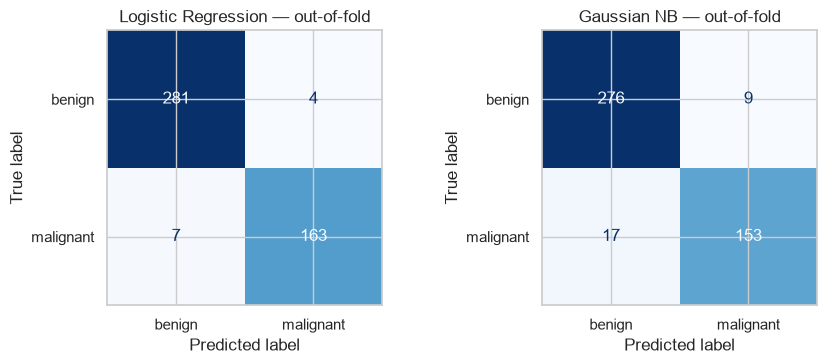

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
oof = {}
for ax, (key, gs) in zip(axes, [("logreg", lr_gs), ("gnb", gnb_gs)]):
    oof[key] = cross_val_predict(gs.best_estimator_, X_train, y_train, cv=get_cv())
    ConfusionMatrixDisplay.from_predictions(y_train, oof[key], display_labels=CLASS_NAMES, cmap="Blues",
                                            colorbar=False, ax=ax)
    ax.set_title(f"{display_name(key)} — out-of-fold")
fig.tight_layout(); savefig(fig, "02_confusion"); plt.show()

In [12]:
err = pd.DataFrame({"true": y_train, "logreg": oof["logreg"], "gnb": oof["gnb"]})
err["lr_wrong"] = err["true"] != err["logreg"]; err["gnb_wrong"] = err["true"] != err["gnb"]
print("errors — LR:", int(err.lr_wrong.sum()), " GNB:", int(err.gnb_wrong.sum()),
      " both:", int((err.lr_wrong & err.gnb_wrong).sum()))
both = err[err.lr_wrong | err.gnb_wrong].join(X_train[["radius_worst", "concave_points_worst", "texture_worst"]])
both.sort_values("true").round(3)

errors — LR: 11  GNB: 26  both: 6


,true,logreg,gnb,lr_wrong,gnb_wrong,radius_worst,concave_points_worst,texture_worst
112,0,0,1,False,True,15.30,0.150,23.73
465,0,0,1,False,True,15.44,0.136,25.50
81,0,1,1,True,True,15.53,0.171,23.19
89,0,0,1,False,True,16.34,0.140,18.24
290,0,0,1,False,True,15.77,0.102,22.13
247,0,0,1,False,True,14.39,0.156,17.70
491,0,0,1,False,True,19.82,0.083,18.42
541,0,1,0,True,False,16.22,0.120,31.73
421,0,0,1,False,True,16.46,0.111,18.34
413,0,1,0,True,False,16.76,0.131,31.55


**Error pattern.** Logistic regression makes 11 out-of-fold errors, GNB 26, and only
6 are shared. LR's mistakes are borderline cases (`radius_worst` ≈ 13–19, moderate
`concave_points_worst`) that sit close to the linear boundary. GNB additionally
labels a group of medium-sized benign tumours (`radius_worst` ≈ 15–16) as malignant
and misses several high-texture malignant ones: its per-feature Gaussian densities
fit the skewed features poorly, and because it treats correlated features as
independent it double-counts the size evidence.